In [2]:
import numpy as np
from matplotlib import pyplot as plt
from skimage import data, color

## Immagini e matrici
Una matrice non deve necessariamente rappresentare soltanto un insieme astratto di numeri.
Possiamo associare a ciascun valore un colore e visualizzare la matrice come un'immagine.

[[0 1 2]
 [3 4 5]
 [6 7 8]]


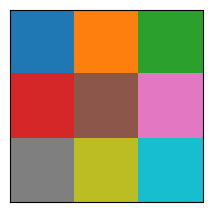

In [3]:
# Matrice 3x3
matrix = np.array([[0, 1, 2],
                   [3, 4, 5],
                   [6, 7, 8]])
print(matrix)
# Se interpreto ciascun numero come un colore, posso visualizzarla come un'immagine
plt.figure(figsize=(2.5, 2.5))
plt.imshow(matrix, cmap="tab10")
plt.xticks([])
plt.yticks([])
plt.show()

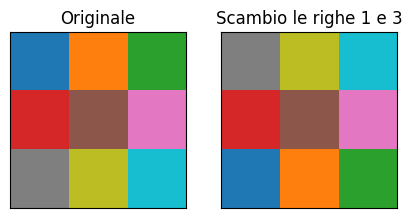

In [4]:
# Scambio la prima riga con la terza
matrix_rows = matrix.copy()
matrix_rows[[0, 2],:] = matrix_rows[[2, 0],:]

fig, ax = plt.subplots(1, 2, figsize=(5, 2.5))
ax[0].imshow(matrix, cmap="tab10")
ax[0].set_title("Originale")
ax[0].set_xticks([])
ax[0].set_yticks([])
ax[1].imshow(matrix_rows, cmap="tab10")
ax[1].set_title("Scambio le righe 1 e 3")
ax[1].set_xticks([])
ax[1].set_yticks([])

plt.show()

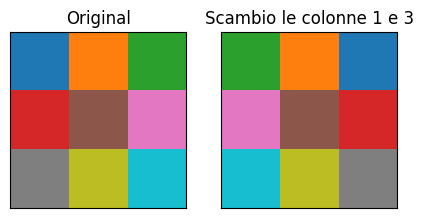

In [ ]:
# Scambio la prima colonna con la terza
matrix_cols = matrix.copy()
matrix_cols[:, [0, 2]] = matrix_cols[:, [2, 0]]

fig, ax = plt.subplots(1, 2, figsize=(5, 2.5))

ax[0].imshow(matrix, cmap="tab10")
ax[0].set_title("Originale")
ax[0].set_xticks([])
ax[0].set_yticks([])
ax[1].imshow(matrix_cols, cmap="tab10")
ax[1].set_title("Scambio le colonne 1 e 3")
ax[1].set_xticks([])
ax[1].set_yticks([])

plt.show()

Aumentando il numero di righe e colonne aumentiamo il numero di pixel.

[0.42767071 0.62617753 0.29325355 0.60096681 0.74691622 0.82388646
 0.70638166 0.77163532 0.27975616 0.99036686]


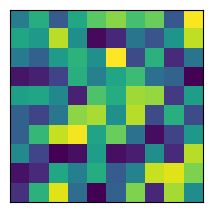

In [ ]:
# Matrice 10x10 random tra 0 e 1
random_image = np.random.random((10, 10))

print(random_image[0,:])

plt.figure(figsize=(2.5, 2.5))
plt.imshow(random_image)
plt.xticks([])
plt.yticks([])
plt.show()


Quando i pixel diventano abbastanza piccoli, non distinguiamo più i singoli elementi della matrice e vediamo semplicemente un'immagine.

In [1]:
# Aumentiamo la dimensione della matrice --> aumentiamo i pixel
random_image = np.random.random((300, 451))

plt.figure(figsize=(5, 4))
plt.imshow(random_image)
plt.xticks([])
plt.yticks([])
plt.show()

print(random_image.shape)
print("Numero di pixel:", random_image.size)

NameError: name 'np' is not defined

In scala di grigi, ogni pixel è descritto da un solo numero.
Supponiamo di avere valori compresi tra 0 e 1:
- 0 = nero
- 1 = bianco
- valori intermedi = diverse tonalità di grigio.

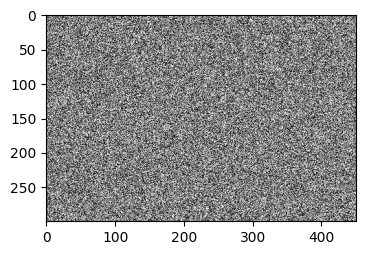

[[0.07270598 0.6051245  0.09449305 0.13354408 0.06275408]
 [0.60637132 0.15432646 0.63442611 0.83719985 0.03984792]
 [0.59353078 0.15654264 0.29890717 0.52518913 0.95015392]
 [0.04378938 0.35942265 0.4087739  0.9282329  0.19525542]
 [0.49233178 0.78764825 0.75159879 0.57324935 0.86433709]]


In [ ]:
# Aumentiamo la dimensione della matrice --> aumentiamo i pixel
random_image = np.random.random((300, 451))

plt.figure(figsize=(5,4))
plt.imshow(random_image, cmap="gray")
# plt.xticks([])
# plt.yticks([])
plt.show()

print(random_image[100:105, 200:205])

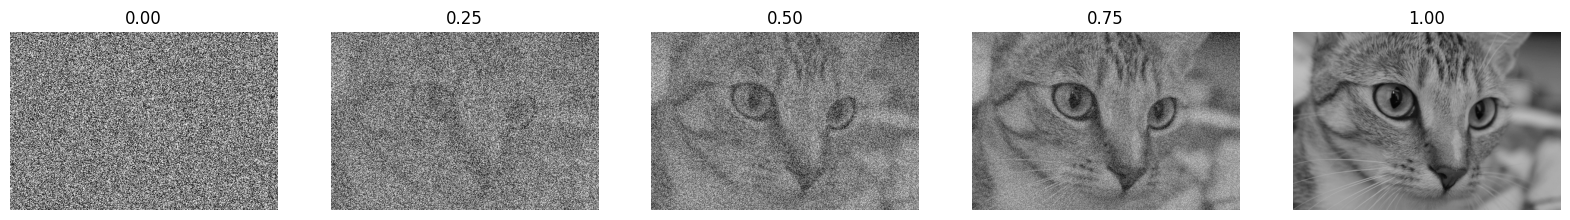

In [9]:
cat = data.chelsea()
cat_gray = color.rgb2gray(cat)
random_image = np.random.random(cat_gray.shape)
alphas = [0, 0.25, 0.5, 0.75, 1]

fig, ax = plt.subplots(1, 5, figsize=(20, 6))

for i, alpha in enumerate(alphas):
    image = (1 - alpha) * random_image + alpha * cat_gray
    ax[i].imshow(image, cmap="gray", vmin=0, vmax=1)
    ax[i].set_title(f"{alpha:.2f}")
    ax[i].axis("off")

plt.show()

(300, 451)


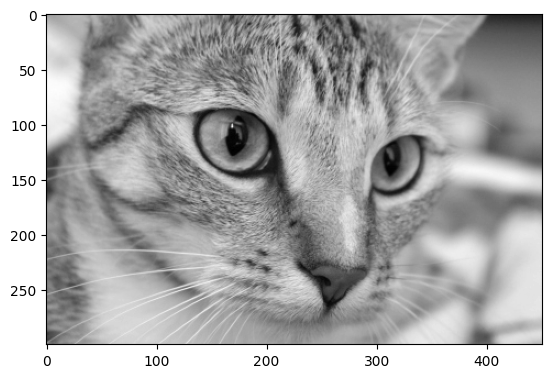

In [11]:
# Immagine in scala di grigi
cat = data.chelsea()
cat_gray = color.rgb2gray(cat)

print(cat_gray.shape)
plt.imshow(cat_gray, cmap="gray")
plt.show()

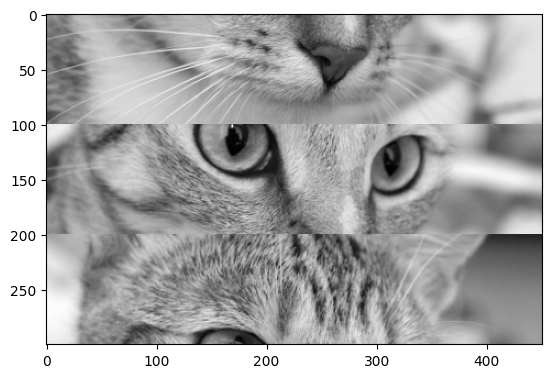

In [12]:
# Scambiamo due blocchi di righe
cat_gray = color.rgb2gray(data.chelsea())

top = cat_gray[:100].copy()
bottom = cat_gray[-100:].copy()

cat_gray[:100] = bottom
cat_gray[-100:] = top

plt.imshow(cat_gray, cmap="gray")
plt.show()

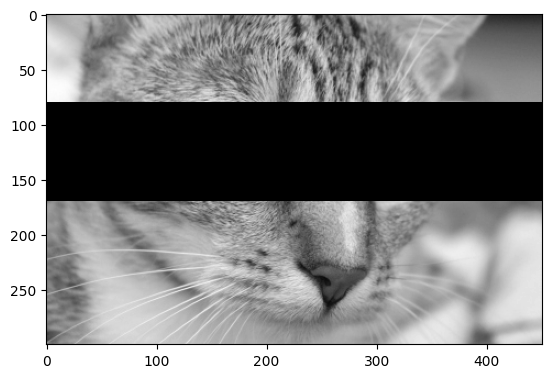

In [13]:
# Oscuriamo un rettangolo
cat_gray = color.rgb2gray(data.chelsea())
cat_gray[80:170, :] = 0

plt.imshow(cat_gray, cmap="gray")
plt.show()

Per un'immagine in scala di grigi basta un numero per ogni pixel.
Per rappresentare un'immagine a colori, invece, utilizziamo tre valori: l'intensità di rosso, verde e blu.
Possiamo quindi pensare a un'immagine RGB come a tre matrici sovrapposte.

(300, 451, 3)
[76 39 13]


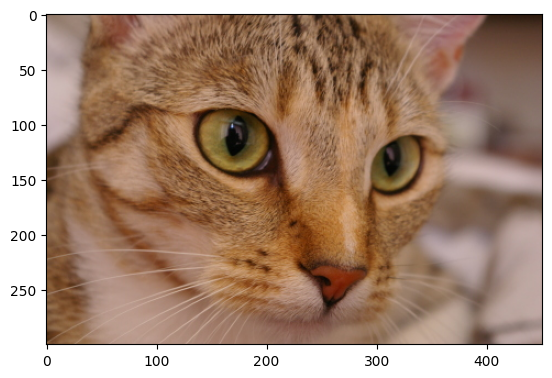

In [14]:
# Immagine rgb
cat = data.chelsea()

print(cat.shape)
print(cat[100, 200])

plt.imshow(cat)
plt.show()


Separiamo i tre contributi.

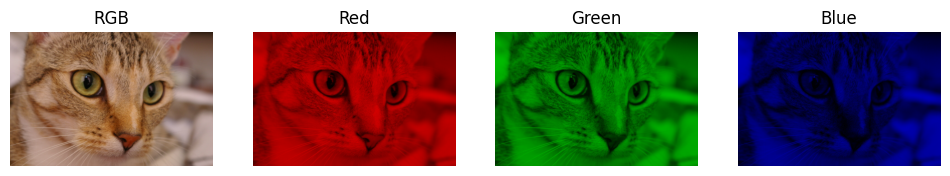

In [15]:
# L'immagine è la sovrapposizione dei tre contributi RGB
red_image = np.zeros_like(cat)
red_image[:, :, 0] = cat[:, :, 0]

green_image = np.zeros_like(cat)
green_image[:, :, 1] = cat[:, :, 1]

blue_image = np.zeros_like(cat)
blue_image[:, :, 2] = cat[:, :, 2]

fig, ax = plt.subplots(1, 4, figsize=(12, 3))

ax[0].imshow(cat)
ax[0].set_title("RGB")

ax[1].imshow(red_image)
ax[1].set_title("Red")

ax[2].imshow(green_image)
ax[2].set_title("Green")

ax[3].imshow(blue_image)
ax[3].set_title("Blue")

for a in ax:
    a.axis("off")

plt.show()

Se li sommiamo nuovamente, ricostruiamo esattamente l'immagine originale.

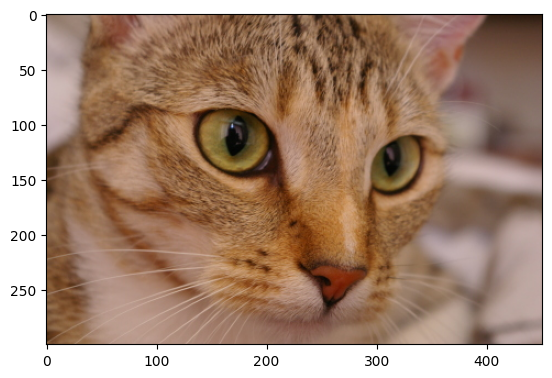

In [55]:
reconstructed = red_image + green_image + blue_image

plt.imshow(reconstructed)
plt.show()

Gli schermi producono i colori combinando luce rossa, verde e blu.
Si tratta di una mescolanza additiva, diversa dalla mescolanza dei pigmenti.

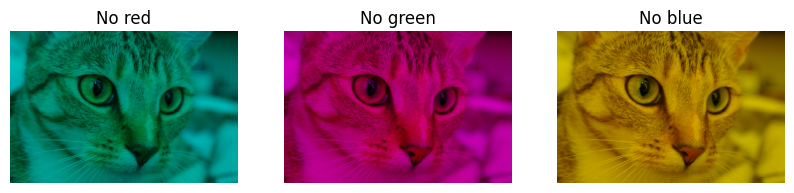

In [16]:
cat_no_red = cat.copy()
cat_no_red[:, :, 0] = 0   # green + blue = cyan
cat_no_green = cat.copy()
cat_no_green[:, :, 1] = 0 # red + blue = magenta
cat_no_blue = cat.copy()
cat_no_blue[:, :, 2] = 0  # red + green = yellow

fig, ax = plt.subplots(1, 3, figsize=(10, 3))

ax[0].imshow(cat_no_red)
ax[0].set_title("No red")

ax[1].imshow(cat_no_green)
ax[1].set_title("No green")

ax[2].imshow(cat_no_blue)
ax[2].set_title("No blue")

for a in ax:
    a.axis("off")

plt.show()

# Uno schermo invece parte dal nero e emette luce attraverso piccoli elementi rossi, verdi e blu. 
# È una mescolanza additiva.

Possiamo manipolare un'immagine semplicemente manipolando gli elementi dell'array. Ad esempio possiamo scambiare il canale rosso con quello blu.

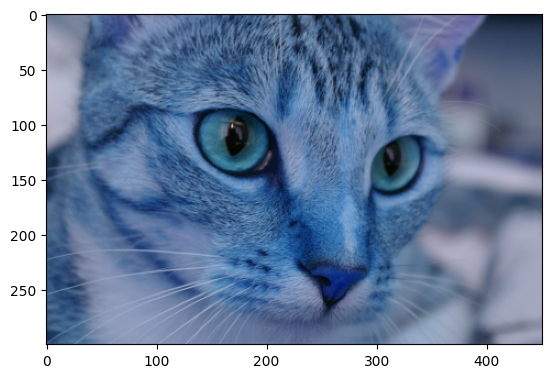

In [ ]:
#
cat_swapped = cat.copy()

cat_swapped[:, :, [0, 2]] = cat_swapped[:, :, [2, 0]]

plt.imshow(cat_swapped)
plt.show()

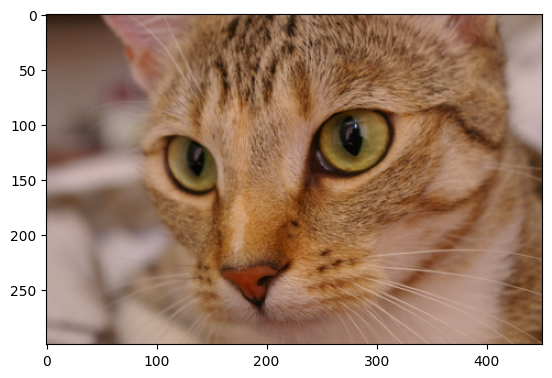

In [30]:
cat_flipped = cat[:, ::-1, :]

plt.imshow(cat_flipped)
plt.show()